In [1]:
from IPython.core.display import display, HTML
import scipy.constants as sc
from scipy.optimize import fsolve
from ipywidgets import interact, widgets
%matplotlib notebook

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as sc
plt.rcParams.update({
    "text.usetex": True,
    'text.latex.preamble': r"\usepackage{amsmath} \boldmath"
})
import os

print(os.getpid())
%cd ../

22036
/media/work/docs/codes/c++/QSVT_framework/simulations


In [2]:
import qiskit
from qiskit.tools.visualization import circuit_drawer
import XW_waves.xw_1d as xw
mix = xw.mix
mse = xw.mse
reload = mix.reload_module

path_results = "./XW_waves/ref-case/figs"

import XW_waves.loc_lib as lib

22036

In [70]:
# -----------------------------------------------
# --- Decompose multi-controlled X gate ---
# -----------------------------------------------
nc = 4
n = nc + 1

obj_reg_target = qiskit.QuantumRegister(1, "t")
qcr = qiskit.QuantumCircuit(obj_reg_target)
obj_reg_control = qiskit.QuantumRegister(nc, "c")
qcr.add_register(obj_reg_control)

qcr.mcx(obj_reg_control, obj_reg_target)

# decomposition:
qcr_new = qcr.decompose()
dc_prev = 0
dc_new = qcr_new.depth()
while dc_prev != dc_new:
    dc_prev = dc_new
    qcr_new = qcr_new.decompose()
    dc_new = qcr_new.depth()

print("nc: ", nc)
print("circuit depth: ", dc_new)
print("N of CNOTs: ", qcr_new.count_ops()["cx"])
qcr.draw(fold=100)
# qcr_new.draw(fold=100)

nc:  4
circuit depth:  59
N of CNOTs:  22


┌─────────┐┌───┐┌──────────┐┌───┐┌─────────┐┌─────────┐┌─────────┐                            »
  t: ┤ U2(0,π) ├┤ X ├┤ U1(-π/4) ├┤ X ├┤ U1(π/4) ├┤ U2(0,π) ├┤ U2(0,π) ├────────────────────────────»
     └─────────┘└─┬─┘└──────────┘└─┬─┘└─────────┘└─────────┘└─────────┘                            »
c_0: ─────────────┼────────────────┼────────────────────────────────────────────────────────────■──»
                  │                │                                                            │  »
c_1: ─────────────┼────────────────┼────────────────────────────────────────────────────────────┼──»
                  │                │                                                            │  »
c_2: ─────────────┼────────────────┼─────────────────────────────■──────────────────────────────┼──»
     ┌─────────┐  │                │  ┌─────────┐┌─────────┐   ┌─┴─┐   ┌──────────┐┌─────────┐┌─┴─┐»
c_3: ┤ U1(π/4) ├──■────────────────■──┤ U2(0,π) ├┤ U1(π/4) ├───┤ X ├───┤ U1(-π/4) ├┤ U2(0,π) ├┤ X ├»
     └─────────┘                      └─────────┘└─────────┘   └───┘   └──────────┘└─────────┘└───┘»
«                                                                                             »
«  t: ────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                             »
«c_0: ──────────────────────────────■─────────────────────────────────────────────────────────»
«                                   │                                                         »
«c_1: ─────────────■────────────────┼───────────────■─────────────────────────────────────────»
«                  │                │               │                                         »
«c_2: ─────────────┼────────────────┼───────────────┼──────────────────────────────────────■──»
«     ┌─────────┐┌─┴─┐┌──────────┐┌─┴─┐┌─────────┐┌─┴─┐┌──────────┐┌─────────┐┌─────────┐┌─┴─┐»
«c_3: ┤ U1(π/4) ├┤ X ├┤ U1(-π/4) ├┤ X ├┤ U1(π/4) ├┤ X ├┤ U1(-π/4) ├┤ U2(0,π) ├┤ U1(π/4) ├┤ X ├»
«     └─────────┘└───┘└──────────┘└───┘└─────────┘└───┘└──────────┘└─────────┘└─────────┘└───┘»
«                                        ┌───┐┌─────────┐┌───┐ ┌──────────┐┌─────────┐┌───┐»
«  t: ───────────────────────────────────┤ X ├┤ U1(π/4) ├┤ X ├─┤ U1(-π/4) ├┤ U2(0,π) ├┤ H ├»
«                                        └─┬─┘└─────────┘└─┬─┘ └──────────┘└─────────┘└───┘»
«c_0: ─────────────────────────────────────┼───────────────┼───────────────────────────────»
«                                          │               │                               »
«c_1: ─────────────────────────────────────┼───────────────┼───────────────────────────────»
«                                          │               │                               »
«c_2: ─────────────────────────────────────┼───────────────┼────────────────────────────■──»
«     ┌──────────┐┌─────────┐┌──────────┐  │               │  ┌───────────┐┌─────────┐┌─┴─┐»
«c_3: ┤ U1(-π/4) ├┤ U2(0,π) ├┤ U1(-π/4) ├──■───────────────■──┤ U2(-2π,π) ├┤ U1(π/4) ├┤ X ├»
«     └──────────┘└─────────┘└──────────┘                     └───────────┘└─────────┘└───┘»
«                                                                                                »
«  t: ───────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                                »
«c_0: ───────────────────────────────────────────────────────■────────────────────────────────■──»
«                                                            │                                │  »
«c_1: ──────────────────────────────────────■────────────────┼───────────────■────────────────┼──»
«                                           │                │               │                │  »
«c_2: ──────────────────────────────────────┼────────────────┼───────────────┼────────────────┼──»
«     ┌──────────┐┌────

<IPython.core.display.Javascript object>


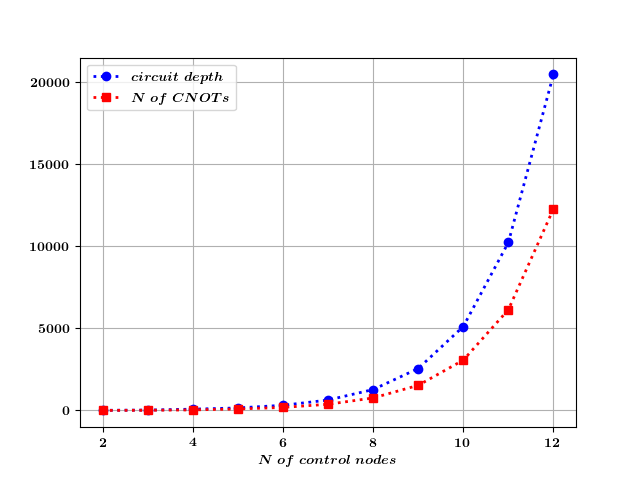

In [71]:
# ----------------------------------------------
# --- Plot the scaling ---
# ----------------------------------------------
nc =  [ 2,  3,  4,   5,   6,   7,    8,    9,   10,    11,    12]
dc =  [11, 27, 81, 156, 316, 636, 1276, 2556, 5116, 10236, 20476]
ncx = [6,  14, 36,  92, 188, 380,  764, 1532, 3068,  6140, 12284]

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(nc, dc, color='b', marker="o", linewidth = 2, linestyle=':', label = "$circuit\ depth$")
ax.plot(nc, ncx, color='r', marker="s", linewidth = 2, linestyle=':', label = "$N\ of\ CNOTs$")
plt.xlabel('$N\ of\ control\ nodes$')
# plt.ylabel("$classical$")
ax.legend()
plt.grid(True)
plt.show()
# plt.savefig(path_fig + label_y + '-real.png')

In [76]:
# -------------------------------------------------------------------
# --- STORE THE RESULTS ---
# -------------------------------------------------------------------
reload(xw)

full_fname = path_results + "/scaling_depth.dat"
mix.save_dat_plot_1d_file(full_fname, nc, dc)

full_fname = path_results + "/scaling_cnots.dat"
mix.save_dat_plot_1d_file(full_fname, nc, ncx)

write data to a file: ./XW_waves/ref-case/figs/scaling_depth.dat
write data to a file: ./XW_waves/ref-case/figs/scaling_cnots.dat


In [6]:

nc = 4
n = nc + 1

obj_reg_target = qiskit.QuantumRegister(1, "t")
qcr = qiskit.QuantumCircuit(obj_reg_target)
obj_reg_control = qiskit.QuantumRegister(nc, "c")
qcr.add_register(obj_reg_control)


# --- multi-controlled X-gate ---
# qcr.mcx(obj_reg_control, obj_reg_target)

# --- decomposed multi-controlled X-gate ---
qcr.cx(obj_reg_control[nc-1], obj_reg_control[nc-2])
for ii in range(1, nc):
    ic = nc - 1 - ii
    it = n - ii - 2
    qcr.x(obj_reg_control[ic])
    qcr.cx(obj_reg_control[ic], it)
    qcr.x(obj_reg_control[ic])
    qcr.cx(obj_reg_control[ic+1], it+1)


print(qcr.draw(fold = 120))
str_wv, pp, qq = lib.Wavefunction_adv(qcr, column=True, systems=[1], width=16)
print(str_wv)






                                   ┌───┐          
  t: ──────────────────────────────┤ X ├──────────
                         ┌───┐┌───┐└─┬─┘┌───┐┌───┐
c_0: ────────────────────┤ X ├┤ X ├──■──┤ X ├┤ X ├
               ┌───┐┌───┐└─┬─┘├───┤┌───┐└───┘└─┬─┘
c_1: ──────────┤ X ├┤ X ├──■──┤ X ├┤ X ├───────■──
     ┌───┐┌───┐└─┬─┘├───┤┌───┐└───┘└─┬─┘          
c_2: ┤ X ├┤ X ├──■──┤ X ├┤ X ├───────■────────────
     └─┬─┘└───┘     └───┘└─┬─┘                    
c_3: ──■───────────────────■──────────────────────
                                                  
        1.000+0.000j |11100>   

